# Python para finanças - visualização de dados financeiros

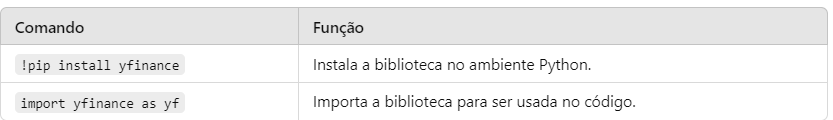

vamos usar nessa curso os dados do site: https://finance.yahoo.com/

In [1]:
!pip install yfinance
%pip install --upgrade nbformat

### instala a biblioteca. ###

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Importação das bibliotecas

In [2]:
%pip install yfinance
%pip install plotly
%pip install pandas
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the 

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
### serve para importar a biblioteca Plotly Express, usada ###
### principalmente para criar gráficos interativos em Python.####
import yfinance as yf

## Base de dados com uma ação

In [4]:
vale = yf.Ticker("VALE3.SA")
período_específico = vale.history(start="2026-01-01", end="2026-08-31")
período_específico.round(2)

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-01-02 00:00:00-03:00,70.36,70.57,69.69,70.40,28418900,0.0,0.0
2026-01-05 00:00:00-03:00,70.42,71.49,70.33,71.12,24958100,0.0,0.0
2026-01-06 00:00:00-03:00,71.45,73.92,70.89,73.80,39536600,0.0,0.0
2026-01-07 00:00:00-03:00,74.02,75.23,73.56,74.24,41501600,0.0,0.0
2026-01-08 00:00:00-03:00,73.73,73.73,72.17,73.52,31894900,0.0,0.0
...,...,...,...,...,...,...,...
2026-08-24 00:00:00-03:00,74.71,78.36,74.71,77.13,28776400,0.0,0.0
2026-08-25 00:00:00-03:00,77.10,78.76,76.89,78.70,18033600,0.0,0.0
2026-08-26 00:00:00-03:00,79.00,79.58,78.21,78.45,13673700,0.0,0.0


Stock Splits significa desdobramento de ações.

É quando uma empresa divide cada ação em várias ações, sem alterar o valor total que o investidor possui.
Por exemplo, imagine que você tenha:

1 ação = R$ 100

A empresa faz um Stock Split de 1 para 5. Você passa a ter:

5 ações = R$ 20 cada

Antes:

1 × 100 reais = 100 reais

Depois:

5 × 20 reais = 100 reais

**moeda = vale.info.get("currency", "Desconhecido")**

**procura dentro dessas informações a chave "currency".**

**Se encontrar → guarda a moeda, por exemplo "BRL".
Se não encontrar → guarda "Desconhecido".**

In [5]:
moeda = vale.info.get("currency", "Desconhecido")
print(f"A ação Vale está cotada em: {moeda}")

A ação Vale está cotada em: BRL


In [6]:
vale_df = yf.download('VALE3.SA', start='2026-01-01',end="2026-08-31")

[*********************100%***********************]  1 of 1 completed


In [7]:
vale_df

Price,Close,High,Low,Open,Volume
Ticker,VALE3.SA,VALE3.SA,VALE3.SA,VALE3.SA,VALE3.SA
Date,,,,,
2026-01-02,70.404411,70.569777,69.694341,70.355781,28418900
2026-01-05,71.124222,71.493847,70.326604,70.423873,24958100
2026-01-06,73.799156,73.915876,70.890762,71.445204,39536600
2026-01-07,74.236870,75.229026,73.555979,74.022873,41501600
2026-01-08,73.517075,73.731071,72.165015,73.731071,31894900
...,...,...,...,...,...
2026-08-24,77.129997,78.360001,74.709999,74.709999,28776400
2026-08-25,78.699997,78.760002,76.889999,77.099998,18033600


In [8]:
vale_df = yf.download('VALE3.SA', start='2026-01-01',end="2026-08-31",  multi_level_index=False)

[*********************100%***********************]  1 of 1 completed


In [9]:
vale_df.round(2)

,Close,High,Low,Open,Volume
Date,,,,,
2026-01-02,70.40,70.57,69.69,70.36,28418900
2026-01-05,71.12,71.49,70.33,70.42,24958100
2026-01-06,73.80,73.92,70.89,71.45,39536600
2026-01-07,74.24,75.23,73.56,74.02,41501600
2026-01-08,73.52,73.73,72.17,73.73,31894900
...,...,...,...,...,...
2026-08-24,77.13,78.36,74.71,74.71,28776400
2026-08-25,78.70,78.76,76.89,77.10,18033600
2026-08-26,78.45,79.58,78.21,79.00,13673700


In [10]:
vale_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 165 entries, 2026-01-02 to 2026-08-28
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   165 non-null    float64
 1   High    165 non-null    float64
 2   Low     165 non-null    float64
 3   Open    165 non-null    float64
 4   Volume  165 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 7.7 KB


In [11]:
vale_df.head(3).round(2)

,Close,High,Low,Open,Volume
Date,,,,,
2026-01-02,70.40,70.57,69.69,70.36,28418900
2026-01-05,71.12,71.49,70.33,70.42,24958100
2026-01-06,73.80,73.92,70.89,71.45,39536600


In [12]:
vale_df.tail(3).round(2)

,Close,High,Low,Open,Volume
Date,,,,,
2026-08-26,78.45,79.58,78.21,79.00,13673700
2026-08-27,79.11,79.30,77.88,78.07,11544100
2026-08-28,78.58,79.48,77.76,79.19,13040900


In [13]:
# Escolher uma data específica (exemplo: 26 de Junho de 2026)
data_especifica = "2026-06-26"

# Selecionar os dados desse dia
preco_no_dia = vale_df.loc[data_especifica].round(2)
print(preco_no_dia)

Close           76.02
High            76.73
Low             75.78
Open            76.05
Volume    25251100.00
Name: 2026-06-26 00:00:00, dtype: float64


In [14]:
vale_df.describe().round(2)

,Close,High,Low,Open,Volume
count,165.00,165.00,165.00,165.00,165.00
mean,78.28,79.15,77.32,78.19,22237246.67
std,4.57,4.62,4.49,4.54,11191752.82
min,69.97,70.57,69.62,70.36,7059500.00
25%,74.54,75.23,73.58,74.30,14222300.00
50%,77.67,78.85,76.89,78.06,18912100.00
75%,81.63,82.76,80.35,81.51,27262900.00
max,87.63,89.12,86.65,87.40,83134600.00


### 📊 Interpretação dos dados – VALE

Foram analisados **165 pregões** da ação VALE3.

- **Preço médio de fechamento:** R\$ 78,28
- **Menor preço de fechamento:** R\$ 69,97
- **Maior preço de fechamento:** R\$ 87,63
- **Mediana do preço de fechamento:** R\$ 77,67
- **Desvio-padrão:** R\$ 4,57
- **Volume médio negociado:** aproximadamente 22,2 milhões de ações

**Interpretação:** A média de R\$ 78,28 está próxima da mediana de R\$ 77,67, indicando que os preços de fechamento ficaram relativamente concentrados em torno desses valores.

O desvio-padrão de R\$ 4,57 indica a variação dos preços de fechamento em relação à média no período analisado.

In [15]:
vale_df[vale_df[('Close')] <= 71.00].round(2)
####verificar a data que ocorreu o valor dessa ação ####

,Close,High,Low,Open,Volume
Date,,,,,
2026-01-02,70.40,70.57,69.69,70.36,28418900
2026-07-08,70.72,73.17,70.38,73.17,29276700
2026-07-13,70.86,72.16,70.47,72.16,16237900
2026-07-16,70.99,72.06,70.56,71.83,12989700
2026-07-17,70.95,71.12,70.13,70.99,13491600
2026-07-20,69.97,71.25,69.75,71.01,13137000
2026-07-21,70.39,70.98,69.62,70.37,12581400


In [16]:
vale_df[(vale_df[('Close')] >= 60) & (vale_df[('Close')] <= 71)].round(2)
   ###para encontrar um preço entre 60 reais e 71 reais

,Close,High,Low,Open,Volume
Date,,,,,
2026-01-02,70.40,70.57,69.69,70.36,28418900
2026-07-08,70.72,73.17,70.38,73.17,29276700
2026-07-13,70.86,72.16,70.47,72.16,16237900
2026-07-16,70.99,72.06,70.56,71.83,12989700
2026-07-17,70.95,71.12,70.13,70.99,13491600
2026-07-20,69.97,71.25,69.75,71.01,13137000
2026-07-21,70.39,70.98,69.62,70.37,12581400


In [17]:
vale_df.to_csv('vale.csv')

In [18]:
vale_df2 = pd.read_csv('/home/mgabriel4/Documentos/GitHub/python-investimentos/semana_5/vale.csv')
vale_df2.round(2)

,Date,Close,High,Low,Open,Volume
0,2026-01-02,70.40,70.57,69.69,70.36,28418900
1,2026-01-05,71.12,71.49,70.33,70.42,24958100
2,2026-01-06,73.80,73.92,70.89,71.45,39536600
3,2026-01-07,74.24,75.23,73.56,74.02,41501600
4,2026-01-08,73.52,73.73,72.17,73.73,31894900
...,...,...,...,...,...,...
160,2026-08-24,77.13,78.36,74.71,74.71,28776400
161,2026-08-25,78.70,78.76,76.89,77.10,18033600
162,2026-08-26,78.45,79.58,78.21,79.00,13673700
163,2026-08-27,79.11,79.30,77.88,78.07,11544100


## Base de dados com mais ações

- **BOVA11**: https://www.sunoresearch.com.br/artigos/bova11/ ---Fundo de Ações----

 A **WEG** é uma empresa multinacional que produz equipamentos eletroeletrônicos, como máquinas elétricas, geradores, transformadores, tintas e vernizes.

    **TOTS**  empresa de Tecnologia TOTVS

In [19]:
acoes = ['VALE3.SA', 'CVCB3.SA', 'WEGE3.SA', 'MGLU3.SA', 'TOTS3.SA', 'BOVA11.SA']

In [20]:
acoes_df = pd.DataFrame()
for acao in acoes:
  acoes_df[acao] = yf.download(acao, start='2026-01-01')['Close']

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [21]:
acoes_df

,VALE3.SA,CVCB3.SA,WEGE3.SA,MGLU3.SA,TOTS3.SA,BOVA11.SA
Date,,,,,,
2026-01-02,70.404411,2.20,47.934109,8.747736,40.350132,157.360001
2026-01-05,71.124222,2.28,47.765224,8.866618,40.763680,158.520004
2026-01-06,73.799156,2.32,47.854630,9.064754,41.630150,160.199997
2026-01-07,74.236870,2.29,47.387711,9.203451,41.915695,158.800003
2026-01-08,73.517075,2.35,45.410740,9.134103,42.693550,159.600006
...,...,...,...,...,...,...
2026-10-23,61.900002,1.57,42.730000,12.690000,44.349998,201.690002
2026-10-26,64.379997,0.98,44.529999,5.300000,37.919998,172.419998
2026-10-27,63.000000,0.96,46.160000,5.750000,35.349998,173.000000


In [22]:
acoes_df = acoes_df.rename(columns={'VALE3.SA': 'VALE', 'CVCB3.SA': 'CVC', 'WEGE3.SA': 'WEGE',
                                    'MGLU3.SA': 'MGLU', 'TOTS3.SA': 'TOTS', 'BOVA11.SA': 'BOVA'}) ### rename renomear as colunas###

In [23]:
acoes_df.columns[0:]

###"Pegue a partir da posição 0 até o final.###

Index(['VALE', 'CVC', 'WEGE', 'MGLU', 'TOTS', 'BOVA'], dtype='str')

In [24]:
acoes_df.round(2)

,VALE,CVC,WEGE,MGLU,TOTS,BOVA
Date,,,,,,
2026-01-02,70.40,2.20,47.93,8.75,40.35,157.36
2026-01-05,71.12,2.28,47.77,8.87,40.76,158.52
2026-01-06,73.80,2.32,47.85,9.06,41.63,160.20
2026-01-07,74.24,2.29,47.39,9.20,41.92,158.80
2026-01-08,73.52,2.35,45.41,9.13,42.69,159.60
...,...,...,...,...,...,...
2026-10-23,61.90,1.57,42.73,12.69,44.35,201.69
2026-10-26,64.38,0.98,44.53,5.30,37.92,172.42
2026-10-27,63.00,0.96,46.16,5.75,35.35,173.00


In [25]:
acoes_df.head().round(2)

,VALE,CVC,WEGE,MGLU,TOTS,BOVA
Date,,,,,,
2026-01-02,70.40,2.20,47.93,8.75,40.35,157.36
2026-01-05,71.12,2.28,47.77,8.87,40.76,158.52
2026-01-06,73.80,2.32,47.85,9.06,41.63,160.20
2026-01-07,74.24,2.29,47.39,9.20,41.92,158.80
2026-01-08,73.52,2.35,45.41,9.13,42.69,159.60


In [26]:
acoes_df.isnull().sum()

VALE    0
CVC     0
WEGE    0
MGLU    0
TOTS    0
BOVA    0
dtype: int64

In [27]:
acoes_df.shape    #### numero de linhas x número de colunas ###

(207, 6)

In [28]:
acoes_df.dropna(inplace=True)  #### remove valores nulos do dataframe ####

In [29]:
acoes_df.shape

(207, 6)

In [30]:
acoes_df.isnull().sum()

VALE    0
CVC     0
WEGE    0
MGLU    0
TOTS    0
BOVA    0
dtype: int64

In [31]:
acoes_df.to_csv('acoes.csv')

In [32]:
acoes_df = pd.read_csv('/home/mgabriel4/Documentos/GitHub/python-investimentos/semana_5/acoes.csv')
acoes_df.round(2)

,Date,VALE,CVC,WEGE,MGLU,TOTS,BOVA
0,2026-01-02,70.40,2.20,47.93,8.75,40.35,157.36
1,2026-01-05,71.12,2.28,47.77,8.87,40.76,158.52
2,2026-01-06,73.80,2.32,47.85,9.06,41.63,160.20
3,2026-01-07,74.24,2.29,47.39,9.20,41.92,158.80
4,2026-01-08,73.52,2.35,45.41,9.13,42.69,159.60
...,...,...,...,...,...,...,...
202,2026-10-23,61.90,1.57,42.73,12.69,44.35,201.69
203,2026-10-26,64.38,0.98,44.53,5.30,37.92,172.42
204,2026-10-27,63.00,0.96,46.16,5.75,35.35,173.00
205,2026-10-28,61.38,0.86,47.20,5.22,34.11,168.47


In [33]:
acoes_df.columns[1:] ### retorna as colunas do dataframe ###

Index(['VALE', 'CVC', 'WEGE', 'MGLU', 'TOTS', 'BOVA'], dtype='str')

In [34]:
acoes_df.describe().round(2)

,VALE,CVC,WEGE,MGLU,TOTS,BOVA
count,207.00,207.00,207.00,207.00,207.00,207.00
mean,76.76,1.80,47.62,7.29,34.54,177.60
std,5.67,0.44,3.12,2.30,4.74,10.63
min,60.05,0.80,41.60,3.88,26.94,157.36
25%,73.03,1.42,45.59,5.04,31.16,170.06
50%,76.77,1.78,47.39,7.15,34.13,175.89
75%,80.81,2.12,50.43,9.15,36.94,183.92
max,87.63,2.72,53.68,13.58,46.62,205.55


## Visualização

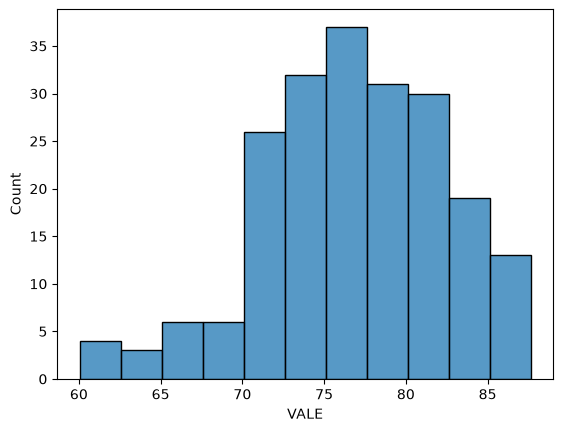

In [35]:
sns.histplot(acoes_df['VALE']);

* usado para criar índices personalizados para iterar sobre colunas específicas;

* serve para manipular subconjuntos de colunas sem incluir todas (por exemplo, ignorar a primeira coluna);

* útil para gráficos ou cálculos envolvendo apenas algumas colunas.

In [36]:
acoes_df

,Date,VALE,CVC,WEGE,MGLU,TOTS,BOVA
0,2026-01-02,70.404411,2.20,47.934109,8.747736,40.350132,157.360001
1,2026-01-05,71.124222,2.28,47.765224,8.866618,40.763680,158.520004
2,2026-01-06,73.799156,2.32,47.854630,9.064754,41.630150,160.199997
3,2026-01-07,74.236870,2.29,47.387711,9.203451,41.915695,158.800003
4,2026-01-08,73.517075,2.35,45.410740,9.134103,42.693550,159.600006
...,...,...,...,...,...,...,...
202,2026-10-23,61.900002,1.57,42.730000,12.690000,44.349998,201.690002
203,2026-10-26,64.379997,0.98,44.529999,5.300000,37.919998,172.419998
204,2026-10-27,63.000000,0.96,46.160000,5.750000,35.349998,173.000000
205,2026-10-28,61.380001,0.86,47.200001,5.220000,34.110001,168.470001


In [37]:
len(acoes_df.columns)  ### número de colunas ####

7

In [38]:
np.arange(1, len(acoes_df.columns))
### len(acoes_df.columns) conta quantas colunas existem no DataFrame.###
###gerar um array NumPy de números inteiros que vai de 1 até len(acoes_df.columns) - 1

array([1, 2, 3, 4, 5, 6])

**7 → divide a figura em 7 linhas
1 → divide a figura em 1 coluna
i + 1 → indica em qual posição o gráfico será desenhado**

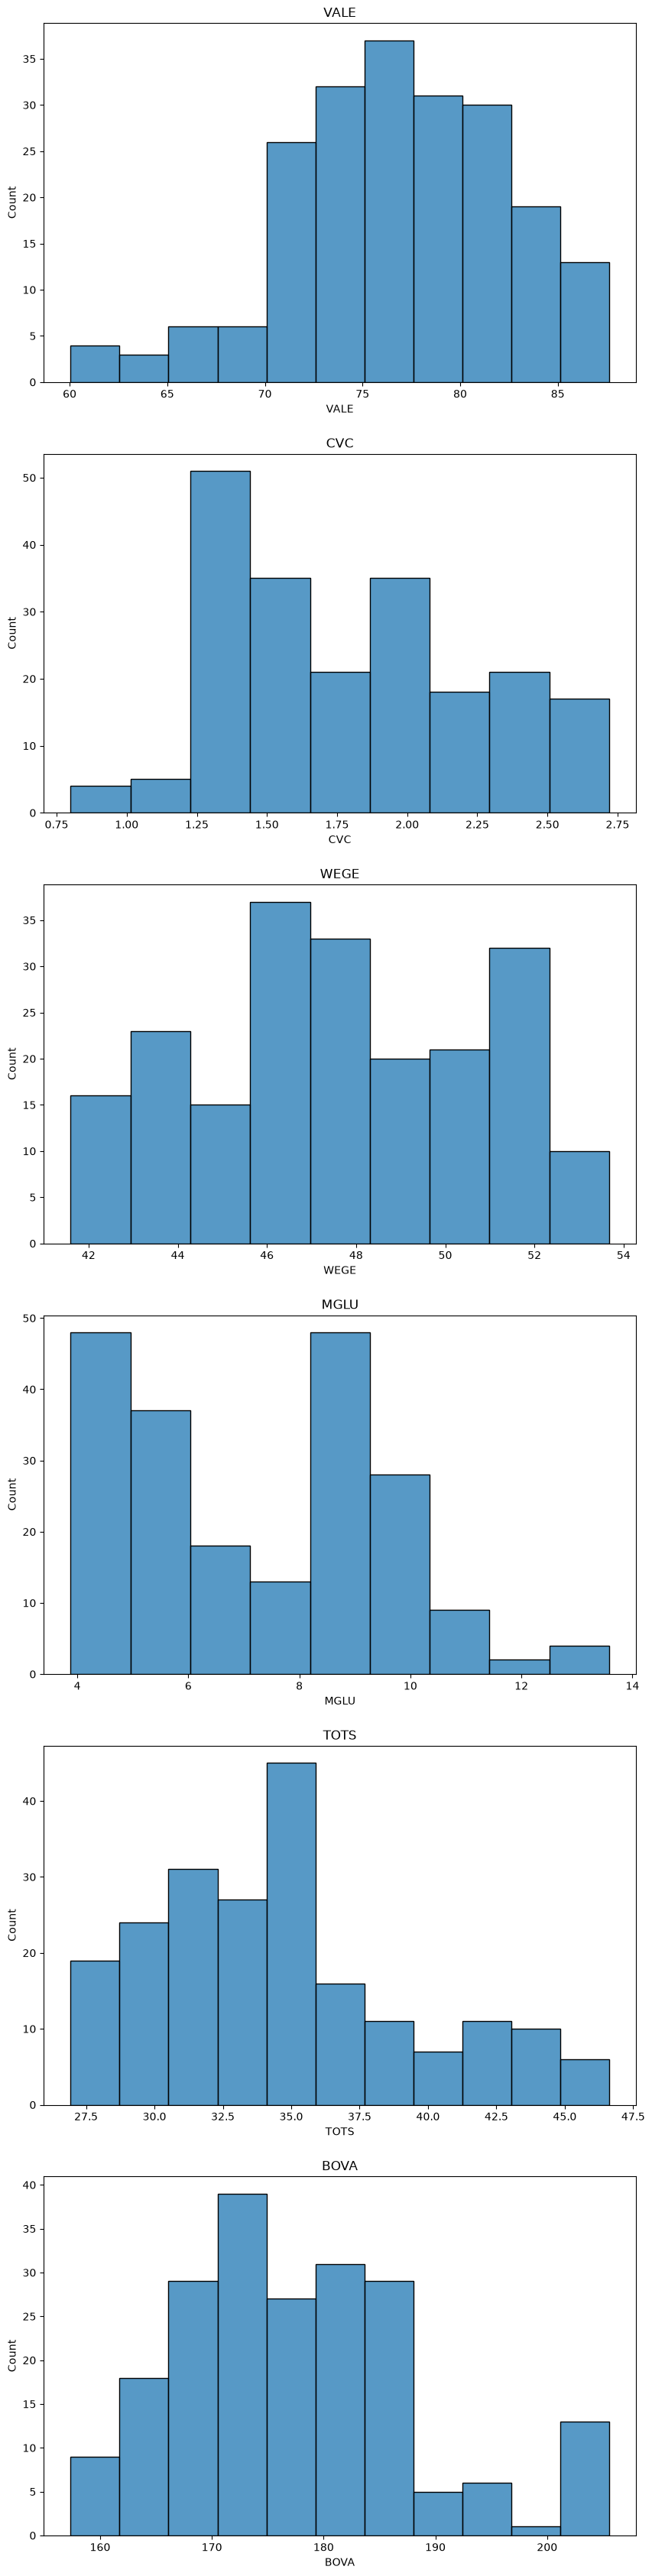

In [39]:
plt.figure(figsize=(10,50))
i = 1
for i in np.arange(1, len(acoes_df.columns)):
  plt.subplot(7, 1, i + 1)
  sns.histplot(acoes_df[acoes_df.columns[i]], kde = False)
  ### kde = False é parar mostrar somente as barras do histograma ###
  plt.title(acoes_df.columns[i])

In [40]:
acoes_df['VALE'].describe()

count    207.000000
mean      76.756381
std        5.672450
min       60.049999
25%       73.025856
50%       76.765907
75%       80.812359
max       87.631020
Name: VALE, dtype: float64

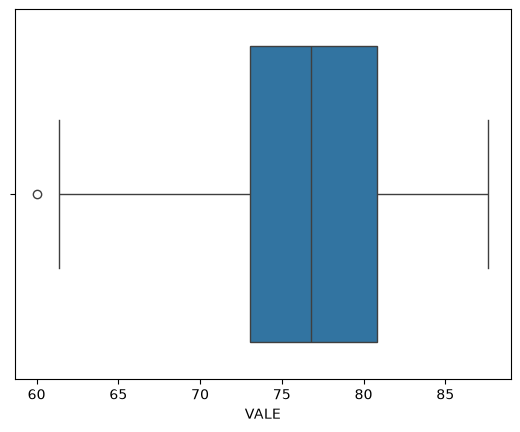

In [41]:
sns.boxplot(x = acoes_df['VALE']);

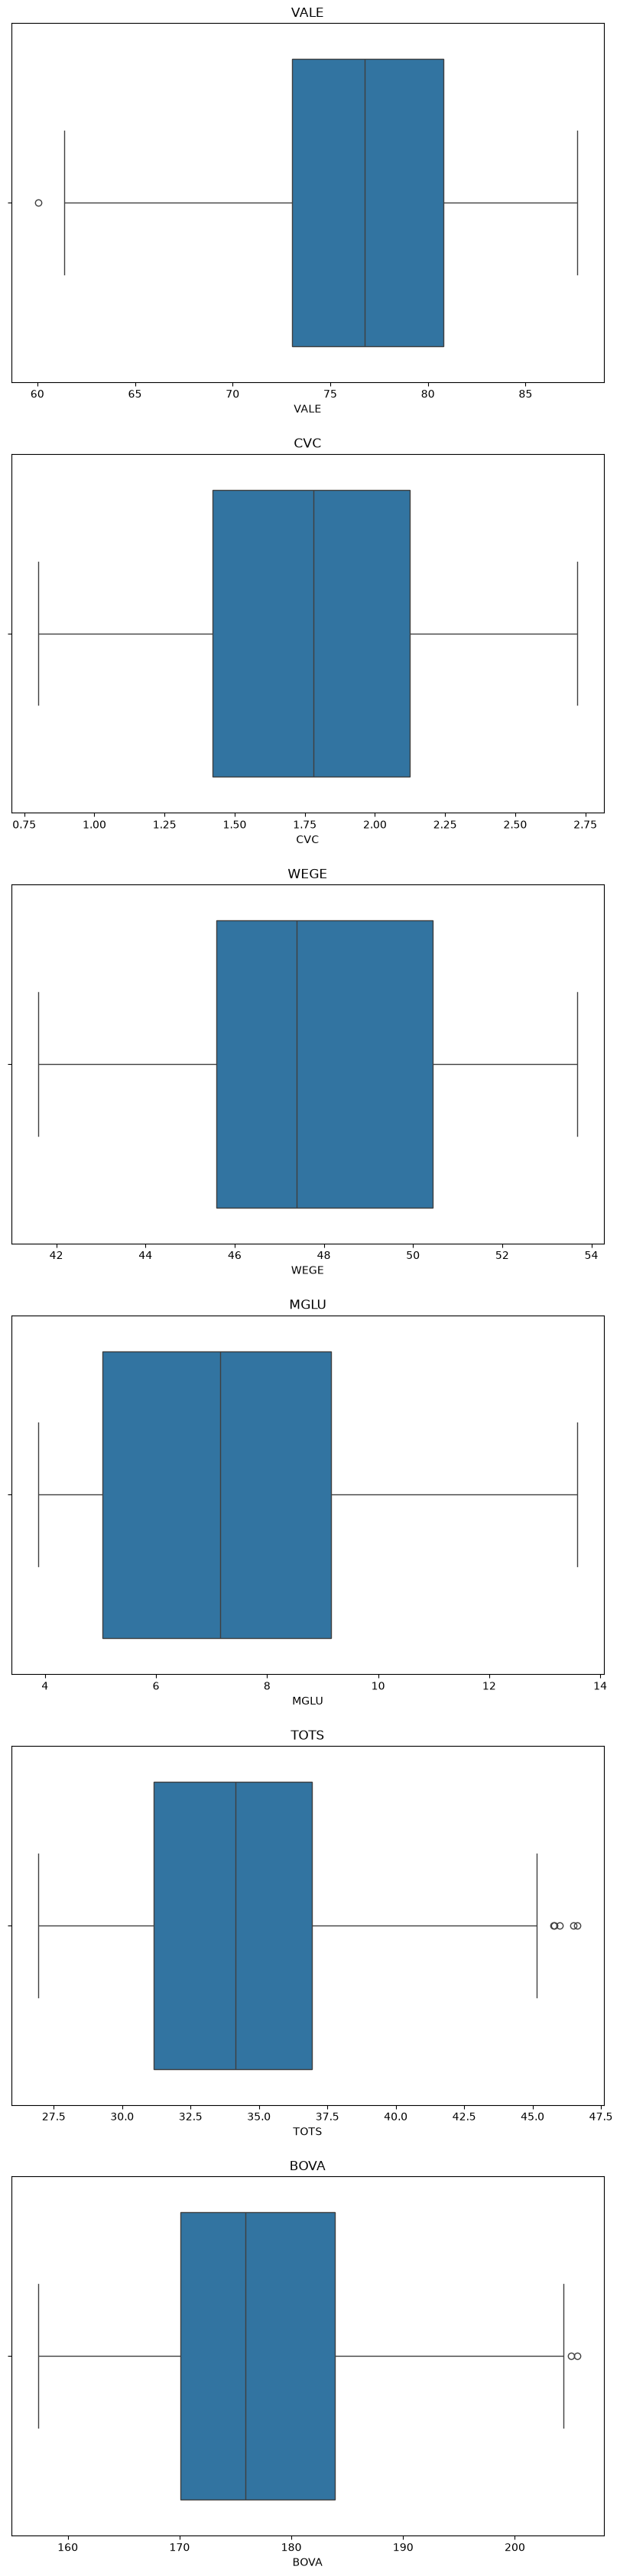

In [42]:
plt.figure(figsize=(10,50))
i = 1
for i in np.arange(1, len(acoes_df.columns)):
  plt.subplot(7, 1, i + 1)
  sns.boxplot(x = acoes_df[acoes_df.columns[i]])
  plt.title(acoes_df.columns[i])

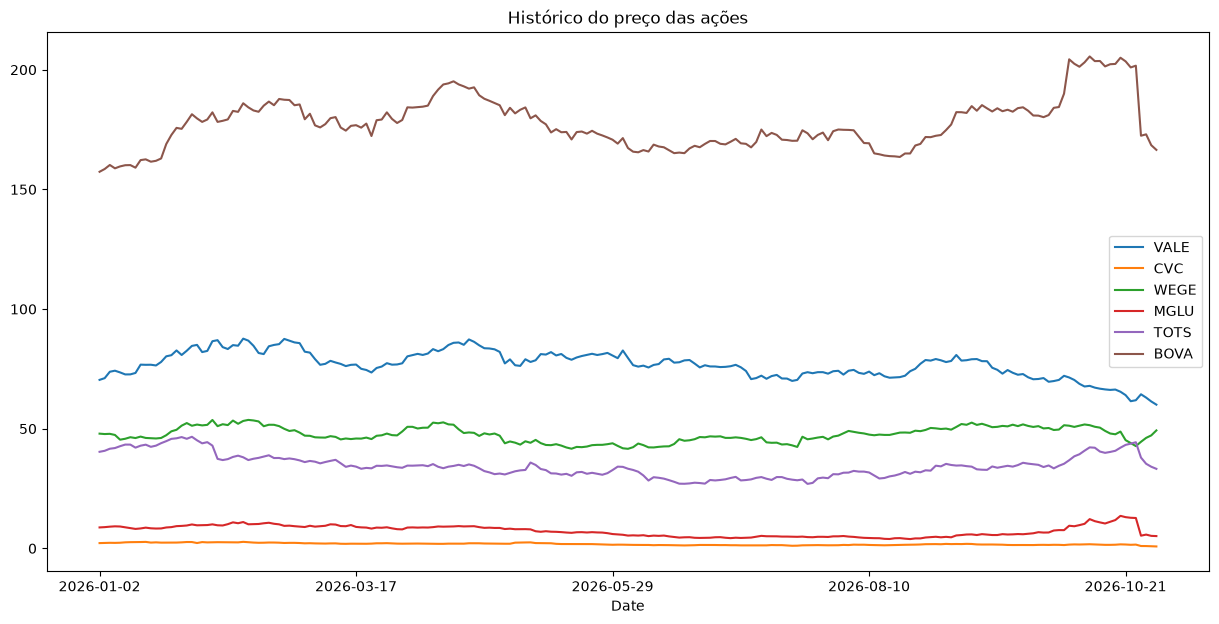

In [43]:
acoes_df.plot(x = 'Date', figsize = (15,7), title = 'Histórico do preço das ações');

In [44]:
acoes_df

,Date,VALE,CVC,WEGE,MGLU,TOTS,BOVA
0,2026-01-02,70.404411,2.20,47.934109,8.747736,40.350132,157.360001
1,2026-01-05,71.124222,2.28,47.765224,8.866618,40.763680,158.520004
2,2026-01-06,73.799156,2.32,47.854630,9.064754,41.630150,160.199997
3,2026-01-07,74.236870,2.29,47.387711,9.203451,41.915695,158.800003
4,2026-01-08,73.517075,2.35,45.410740,9.134103,42.693550,159.600006
...,...,...,...,...,...,...,...
202,2026-10-23,61.900002,1.57,42.730000,12.690000,44.349998,201.690002
203,2026-10-26,64.379997,0.98,44.529999,5.300000,37.919998,172.419998
204,2026-10-27,63.000000,0.96,46.160000,5.750000,35.349998,173.000000
205,2026-10-28,61.380001,0.86,47.200001,5.220000,34.110001,168.470001


In [45]:
acoes_df_normalizado = acoes_df.copy()
for i in acoes_df_normalizado.columns[1:]:
  acoes_df_normalizado[i] = acoes_df_normalizado[i] / acoes_df_normalizado[i][0]

Por que isso é útil?

✅ Comparação de desempenho: Mesmo que as ações tenham preços absolutos diferentes, após a normalização, podemos comparar suas variações ao longo do tempo.

✅ Facilidade de análise: Um gráfico dos dados normalizados mostraria a performance relativa de cada ação desde o ponto inicial.

✅ Aplicação em estratégias financeiras: Esse método é comum na análise de carteiras de investimento e séries temporais.

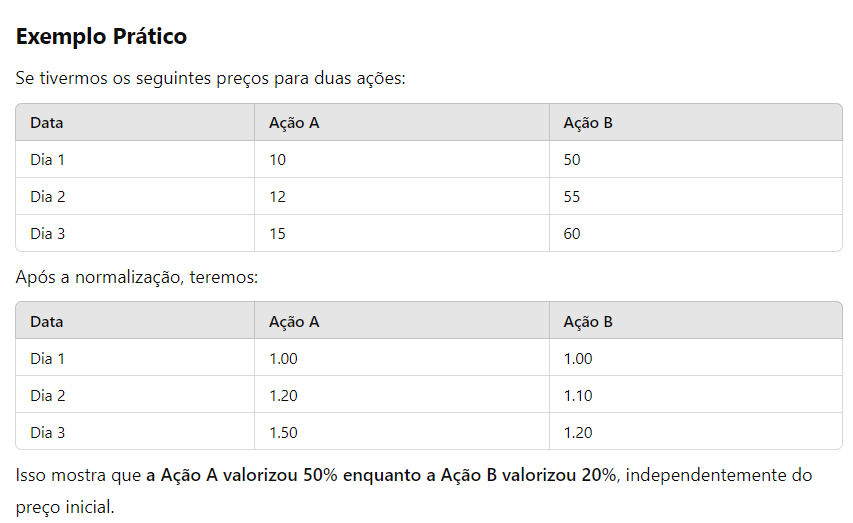

O cálculo utilizado no código é a normalização baseada no valor inicial. Essa técnica transforma os preços das ações em uma escala relativa ao primeiro valor disponível.

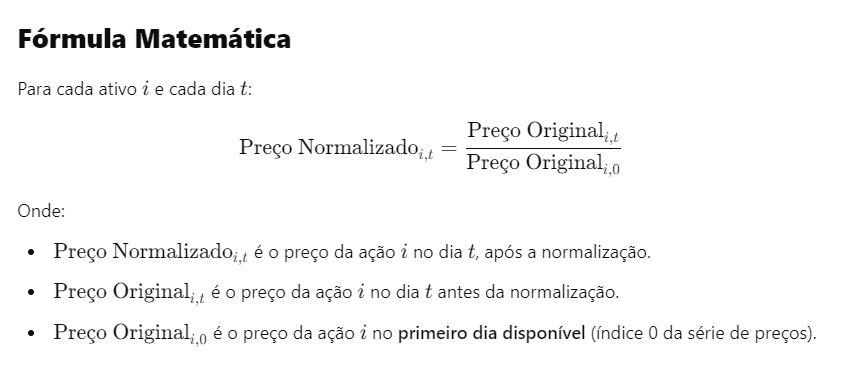

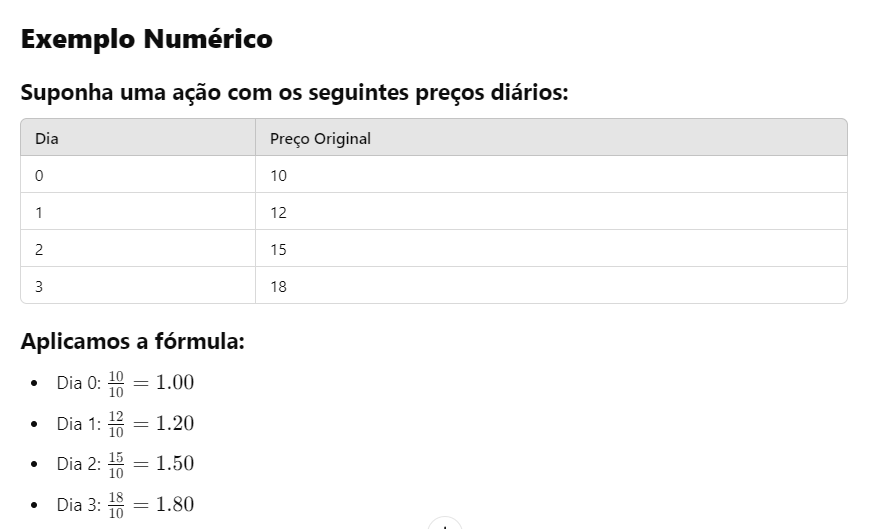

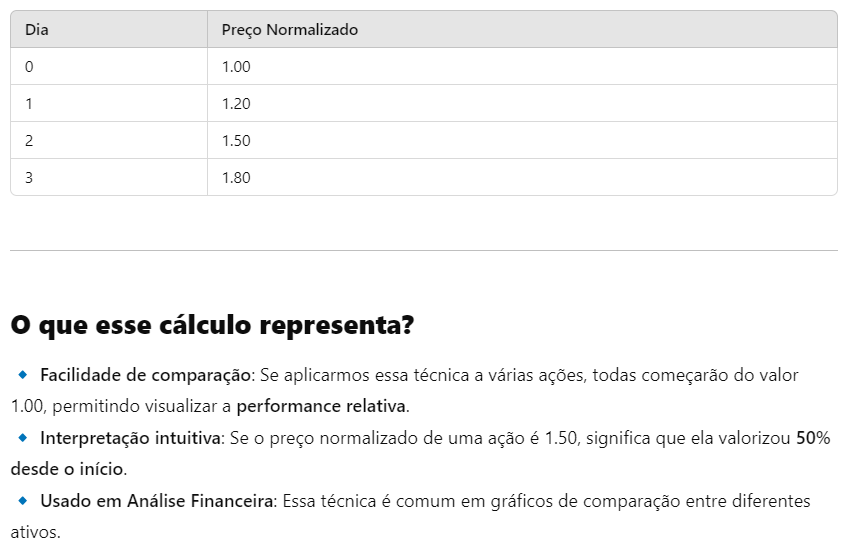

In [46]:
acoes_df_normalizado

,Date,VALE,CVC,WEGE,MGLU,TOTS,BOVA
0,2026-01-02,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,2026-01-05,1.010224,1.036364,0.996477,1.013590,1.010249,1.007372
2,2026-01-06,1.048218,1.054545,0.998342,1.036240,1.031723,1.018048
3,2026-01-07,1.054435,1.040909,0.988601,1.052095,1.038799,1.009151
4,2026-01-08,1.044211,1.068182,0.947358,1.044168,1.058077,1.014235
...,...,...,...,...,...,...,...
202,2026-10-23,0.879206,0.713636,0.891432,1.450661,1.099129,1.281711
203,2026-10-26,0.914431,0.445455,0.928984,0.605871,0.939774,1.095704
204,2026-10-27,0.894830,0.436364,0.962989,0.657313,0.876081,1.099390
205,2026-10-28,0.871820,0.390909,0.984685,0.596726,0.845350,1.070602


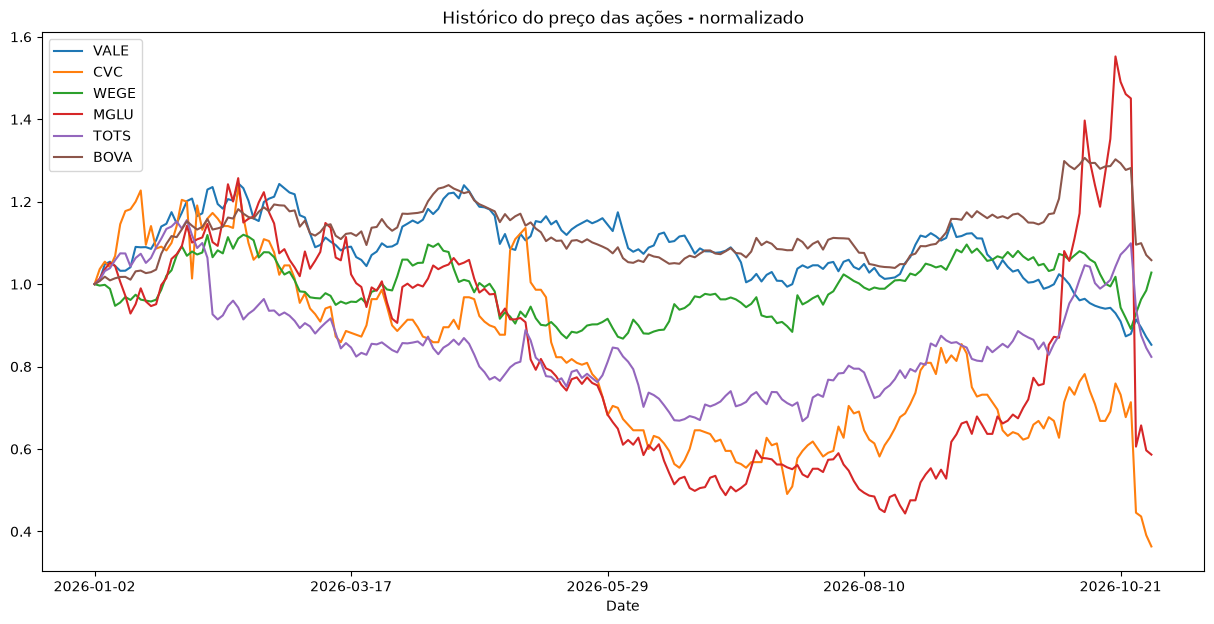

In [47]:
acoes_df_normalizado.plot(x = 'Date', figsize = (15,7), title = 'Histórico do preço das ações - normalizado');

In [48]:
figura = px.line(title = 'Histórico do preço das ações')
for i in acoes_df.columns[1:]:
  figura.add_scatter(x = acoes_df['Date'], y = acoes_df[i], name = i)
figura.show()

In [49]:
figura = px.line(title = 'Histórico do preço das ações - normalizado')
for i in acoes_df_normalizado.columns[1:]:
  figura.add_scatter(x = acoes_df_normalizado['Date'], y = acoes_df_normalizado[i], name = i)
figura.show()